# Pourquoi les vols américains sont-ils en retard ?

**Auteur :** Cheikh Mouhamadou Habib FALL · [github.com/habibfl](https://github.com/habibfl)

Ce notebook analyse **tous les vols intérieurs des grandes compagnies américaines en 2024 et 2025**, croisés avec la météo horaire de leur aéroport de départ.

**Sources**
- **BTS** (Bureau of Transportation Statistics) : chaque vol, avec ses horaires prévus et réels, ses annulations et la cause déclarée de son retard.
- **Open-Meteo** : météo horaire (température, pluie, neige, vent, rafales) des 50 aéroports les plus fréquentés.
- **OurAirports** : noms et coordonnées des aéroports.

**Définition utilisée partout :** un vol est **en retard** s'il arrive avec **15 minutes ou plus** de retard, la définition officielle du BTS.

**Questions**
1. Quelle est l'ampleur du problème, et varie-t-elle dans l'année ?
2. D'où viennent les minutes de retard ?
3. La météo au départ change-t-elle vraiment la donne ?
4. Un avion en retard contamine-t-il ses vols suivants ?
5. Quelles compagnies et quels aéroports sont les plus fiables, et ce classement est-il stable ?

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy import stats

import fd_data as fd
import fd_style as fs

fs.apply()
pd.set_option("display.precision", 2)
con = fd.connect()

## 1. Chargement et contrôle qualité

L'entrepôt DuckDB est construit par `pipeline/run_pipeline.py`. Les agrégations se font directement en SQL dans DuckDB : pandas ne reçoit que des résultats de quelques centaines de lignes, ce qui permet de travailler sur des millions de vols sur un ordinateur portable.

In [2]:
n = fd.query("SELECT COUNT(*) n, MIN(flight_date) d0, MAX(flight_date) d1, COUNT(DISTINCT carrier_code) c, COUNT(DISTINCT origin) a FROM fact_flights", con).iloc[0]
print(f"Vols          : {fd.fmt(n.n)}")
print(f"Période       : {n.d0:%d/%m/%Y} au {n.d1:%d/%m/%Y}")
print(f"Compagnies    : {n.c}")
print(f"Aéroports     : {n.a} aéroports de départ")
fd.query("SELECT * FROM quality_checks", con)

Vols          : 14 080 680
Période       : 01/01/2024 au 31/12/2025
Compagnies    : 15
Aéroports     : 358 aéroports de départ


,check_name,value,passed
0,Vols chargés,14080680,True
1,"Doublons (date, compagnie, vol, départ, heure)",0,True
2,Aéroports de départ sans référentiel,1,True
3,Compagnies sans nom,0,True
4,Vols annulés avec un retard à l'arrivée,0,True
5,Part des retards dont les causes somment au re...,100.0,True
6,Part des vols croisés avec la météo (%),78.5,True
7,Jours sans vol dans la période,0,True


Part des vols croisés avec la météo : 78.6%


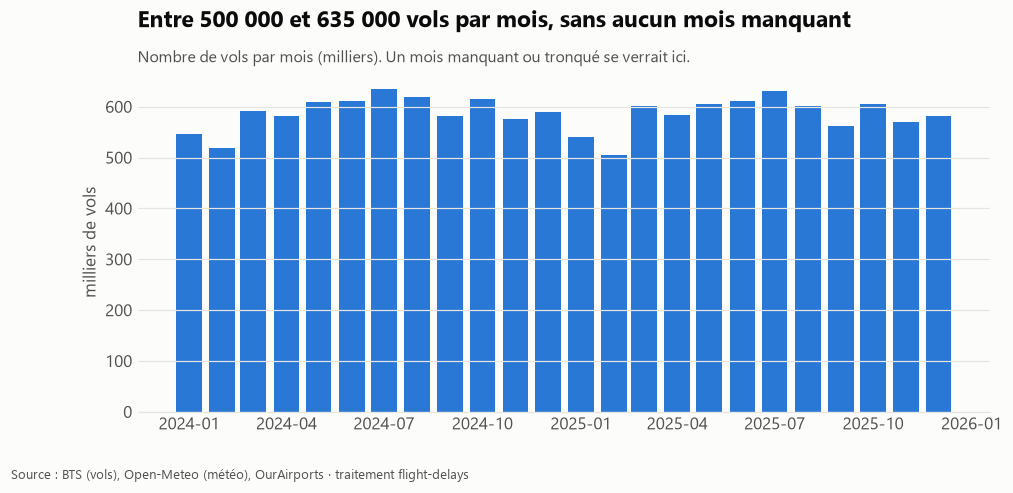

In [3]:
monthly = fd.query("""
    SELECT DATE_TRUNC('month', flight_date) AS mois, COUNT(*) AS vols,
           AVG(CASE WHEN weather_condition IS NOT NULL THEN 1 ELSE 0 END) AS part_meteo
    FROM fact_flights GROUP BY 1 ORDER BY 1""", con)

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(monthly.mois, monthly.vols / 1e3, width=24, color=fs.BLUE)
ax.set_title("Entre 500 000 et 635 000 vols par mois, sans aucun mois manquant")
fs.subtitle(ax, "Nombre de vols par mois (milliers). Un mois manquant ou tronqué se verrait ici.")
ax.set_ylabel("milliers de vols")
fs.source(fig)
fs.save(fig, "01_vols_par_mois")
print(f"Part des vols croisés avec la météo : {monthly.part_meteo.mean():.1%}")

*La météo n'est récupérée que pour les 50 aéroports de départ les plus fréquentés : les vols partant d'aéroports plus petits n'ont pas de météo. Les analyses météo portent donc sur ces 50 aéroports, qui concentrent la grande majorité du trafic.*

## 2. Question 1 : quelle est l'ampleur du problème ?

In [4]:
k = fd.query("""
    SELECT AVG(is_delayed::INT) AS retard, AVG(is_cancelled::INT) AS annule,
           AVG(arr_delay_min) FILTER (WHERE is_delayed) AS retard_moyen,
           SUM(GREATEST(arr_delay_min, 0)) / 60 AS heures_perdues
    FROM fact_flights""", con).iloc[0]
print(f"Vols en retard (15 min et plus) : {k.retard:.1%}")
print(f"Vols annulés                    : {k.annule:.2%}")
print(f"Retard moyen d'un vol en retard : {k.retard_moyen:.0f} min")
print(f"Heures de retard cumulées       : {fd.fmt(k.heures_perdues)} h")

Vols en retard (15 min et plus) : 21.2%
Vols annulés                    : 1.41%
Retard moyen d'un vol en retard : 72 min
Heures de retard cumulées       : 3 825 064 h


year,2024,2025
month,,
1,23.1,18.2
2,15.8,20.4
3,20.6,19.3
4,18.9,19.5
5,26.0,23.3
6,24.5,27.7
7,28.7,28.0
8,22.9,22.2
9,15.4,16.5


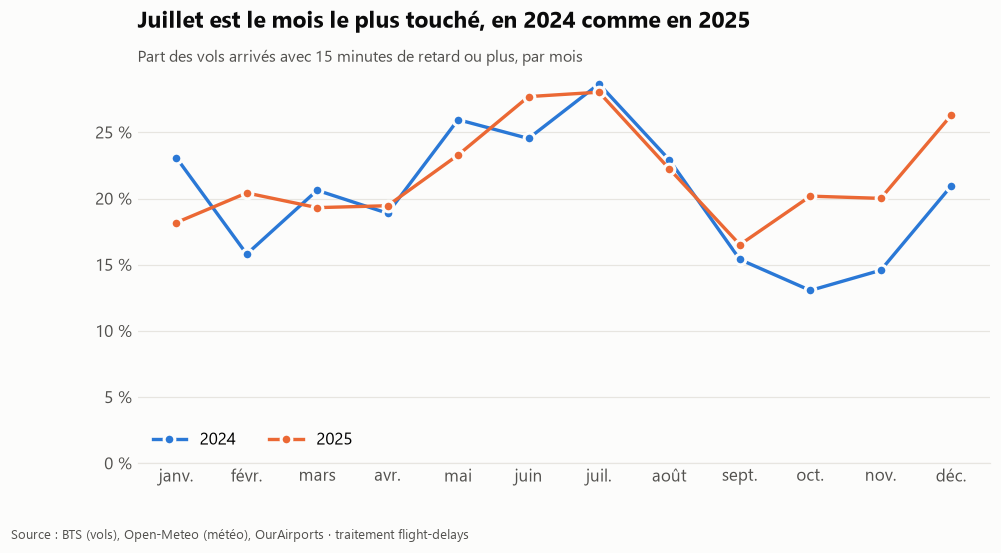

In [5]:
m = fd.query("""
    SELECT d.year, d.month, ANY_VALUE(d.month_name) AS nom, AVG(f.is_delayed::INT) * 100 AS pct
    FROM fact_flights f JOIN dim_date d ON d.date = f.flight_date
    GROUP BY 1, 2 ORDER BY 1, 2""", con)

fig, ax = plt.subplots(figsize=(10, 4.6))
for i, (year, g) in enumerate(m.groupby("year")):
    ax.plot(g.month, g.pct, color=fs.SERIES[i], lw=2.2, marker="o", ms=7,
            markeredgecolor=fs.SURFACE, markeredgewidth=2, label=str(year))
ax.legend(loc="lower left", ncol=2)
ax.set_xticks(range(1, 13), m.drop_duplicates("month").sort_values("month").nom)
fs.pct_axis(ax)
ax.set_ylim(bottom=0)
ax.set_title("Juillet est le mois le plus touché, en 2024 comme en 2025")
fs.subtitle(ax, "Part des vols arrivés avec 15 minutes de retard ou plus, par mois")
fs.source(fig)
fs.save(fig, "02_saisonnalite")
m.pivot(index="month", columns="year", values="pct").round(1)

### Ce qu'il faut retenir

- **Environ un vol sur cinq (21,2 %) arrive avec 15 minutes de retard ou plus**, et 1,4 % sont annulés. Un vol en retard l'est de 72 minutes en moyenne : au total, 3,8 millions d'heures de retard en deux ans.
- **Juillet est le pire mois les deux années (28-29 %).** Sur l'ensemble des deux ans, septembre est le plus calme (16 %).
- **Octobre et novembre 2025 sortent du lot** : 20 % de retards contre 13 et 15 % un an plus tôt. Ces deux mois coïncident avec le shutdown du gouvernement fédéral (1er octobre au 12 novembre 2025), pendant lequel les contrôleurs aériens ont travaillé sans salaire et la FAA a imposé des réductions de vols. Les données montrent la coïncidence ; elles ne prouvent pas à elles seules la cause.

## 3. Question 2 : d'où viennent les minutes de retard ?

Pour chaque vol arrivé avec 15 minutes de retard ou plus, la compagnie déclare comment se répartissent les minutes entre cinq causes :
- **Compagnie** : maintenance, équipage, nettoyage, bagages, carburant ;
- **Avion en retard** : l'appareil est arrivé en retard de son vol précédent ;
- **Trafic aérien (NAS)** : contrôle aérien, saturation de l'aéroport, et une partie de la météo (une météo moyenne qui ralentit le trafic est classée ici) ;
- **Météo** : météo extrême uniquement (tempête, neige forte) ;
- **Sécurité**.

Avion en retard    39.8
Compagnie          33.4
Trafic aérien      20.4
Météo extrême       6.2
Sécurité            0.2
Name: 0, dtype: float64

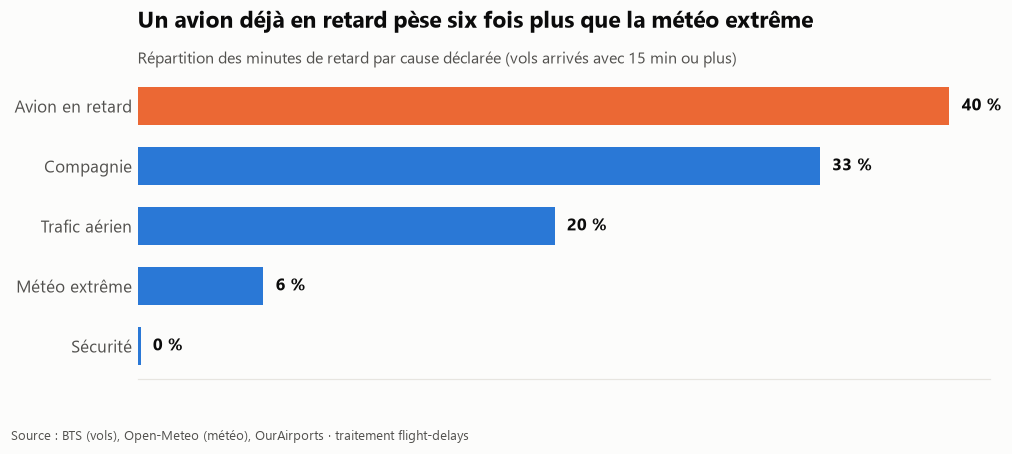

In [6]:
causes = fd.query("""
    SELECT SUM(delay_carrier_min) AS "Compagnie", SUM(delay_late_aircraft_min) AS "Avion en retard",
           SUM(delay_nas_min) AS "Trafic aérien", SUM(delay_weather_min) AS "Météo extrême",
           SUM(delay_security_min) AS "Sécurité"
    FROM fact_flights WHERE is_delayed""", con).T[0].sort_values()
part = causes / causes.sum() * 100

fig, ax = plt.subplots(figsize=(10, 3.6))
colors = [fs.ORANGE if c == "Avion en retard" else fs.BLUE for c in part.index]
ax.barh(part.index, part.values, color=colors, height=0.62)
for i, v in enumerate(part.values):
    ax.text(v + 0.6, i, f"{v:.0f} %", va="center", color=fs.INK, fontweight="bold")
ax.grid(False)
ax.set_xticks([])
ax.set_title("Un avion déjà en retard pèse six fois plus que la météo extrême")
fs.subtitle(ax, "Répartition des minutes de retard par cause déclarée (vols arrivés avec 15 min ou plus)")
fs.source(fig)
fs.save(fig, "03_causes")
part.round(1)[::-1]

*La cause est déclarée par la compagnie, pas mesurée. Et la météo est en partie cachée dans « Trafic aérien ». C'est pour cela que la question suivante mesure l'effet de la météo autrement : en croisant chaque vol avec la météo réelle de son aéroport de départ.*

## 4. Question 3 : la météo au départ change-t-elle vraiment la donne ?

### 4.1 Taux de retard selon le temps qu'il fait au décollage

Test du khi-deux d'indépendance : khi2 = 122,788, p = 0.0e+00


,meteo,vols,pct_retard,ic_bas,ic_haut,pct_annule
0,Dégagé,5489503,19.47,19.44,19.51,0.92
1,Nuageux,4013557,21.50,21.46,21.54,1.30
2,Bruine,1172079,27.96,27.88,28.05,2.30
3,Pluie,281779,35.67,35.50,35.85,4.58
4,Neige,103249,49.72,49.42,50.03,10.03


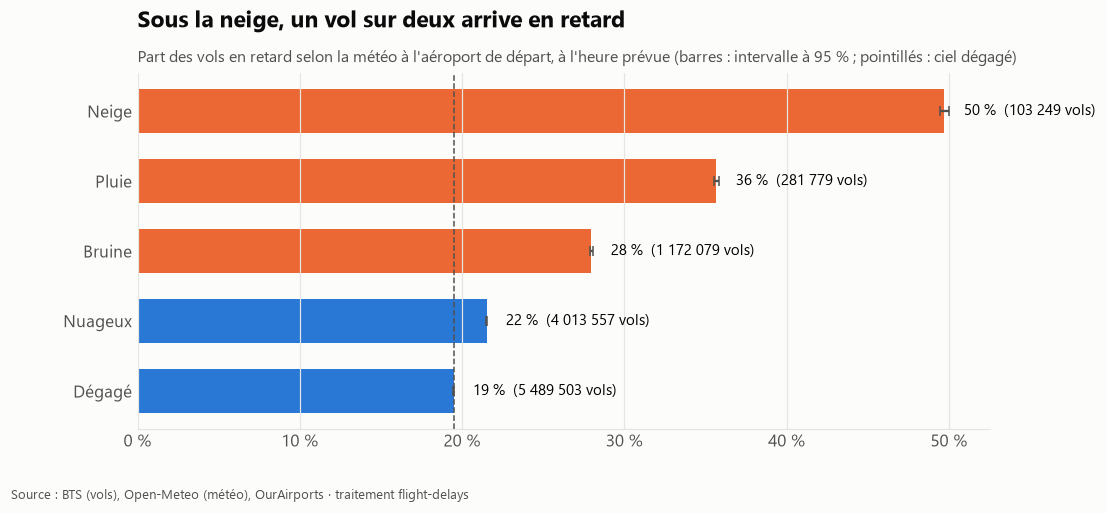

In [7]:
def wilson(k, n, z=1.96):
    """Intervalle de confiance à 95 % d'une proportion (méthode de Wilson)."""
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    demi = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - demi, centre + demi

w = fd.query("""
    SELECT weather_condition AS meteo, COUNT(*) AS vols,
           SUM(is_delayed::INT) AS retards, SUM(is_cancelled::INT) AS annules
    FROM fact_flights WHERE weather_condition IS NOT NULL
    GROUP BY 1""", con)
w["pct_retard"] = w.retards / w.vols * 100
w["pct_annule"] = w.annules / w.vols * 100
lo, hi = wilson(w.retards, w.vols)
w["ic_bas"], w["ic_haut"] = lo * 100, hi * 100
w = w.sort_values("pct_retard")

ref = w.loc[w.meteo == "Dégagé", "pct_retard"].iloc[0]
fig, ax = plt.subplots(figsize=(10, 4.2))
colors = [fs.ORANGE if p > ref * 1.25 else fs.BLUE for p in w.pct_retard]
ax.barh(w.meteo, w.pct_retard, color=colors, height=0.62,
        xerr=[w.pct_retard - w.ic_bas, w.ic_haut - w.pct_retard], ecolor=fs.MUTED, capsize=3)
ax.axvline(ref, color=fs.MUTED, lw=1, ls="--")
for i, (v, n) in enumerate(zip(w.pct_retard, w.vols)):
    ax.text(v + 1.2, i, f"{v:.0f} %  ({fd.fmt(n)} vols)", va="center", fontsize=9.5)
fs.pct_axis(ax, "x")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title("Sous la neige, un vol sur deux arrive en retard")
fs.subtitle(ax, "Part des vols en retard selon la météo à l'aéroport de départ, à l'heure prévue (barres : intervalle à 95 % ; pointillés : ciel dégagé)")
fs.source(fig)
fs.save(fig, "04_meteo_conditions")

chi2, pval, dof, _ = stats.chi2_contingency(np.c_[w.retards, w.vols - w.retards])
print(f"Test du khi-deux d'indépendance : khi2 = {chi2:,.0f}, p = {pval:.1e}")
w[["meteo", "vols", "pct_retard", "ic_bas", "ic_haut", "pct_annule"]].round(2)

,rafales,vols,pct_retard,pct_annule
0,0,740150,17.73,1.19
1,10,3451945,19.22,1.21
2,20,3456335,22.12,1.29
3,30,2067479,23.96,1.45
4,40,908646,25.20,1.67
5,50,318296,27.64,2.10
6,60,93929,33.13,3.55
7,70,18215,38.06,6.51
8,80,5172,42.40,20.73


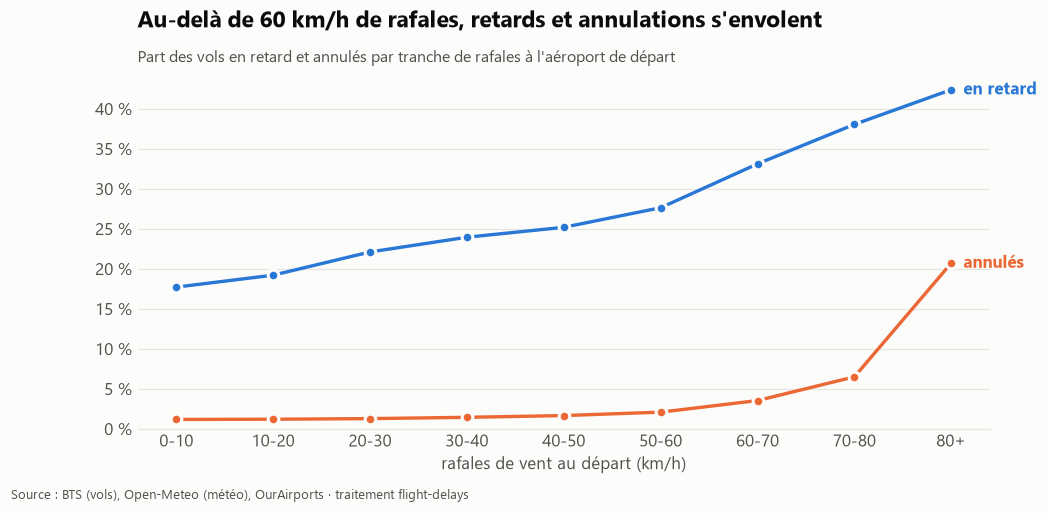

In [8]:
g = fd.query("""
    SELECT LEAST(FLOOR(gusts_kmh / 10) * 10, 80)::INT AS rafales, COUNT(*) AS vols,
           AVG(is_delayed::INT) * 100 AS pct_retard, AVG(is_cancelled::INT) * 100 AS pct_annule
    FROM fact_flights WHERE gusts_kmh IS NOT NULL GROUP BY 1 ORDER BY 1""", con)
g = g[g.vols >= 500]

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(g.rafales, g.pct_retard, color=fs.BLUE, lw=2.2, marker="o", ms=7, markeredgecolor=fs.SURFACE, markeredgewidth=2, label="en retard")
ax.plot(g.rafales, g.pct_annule, color=fs.ORANGE, lw=2.2, marker="o", ms=7, markeredgecolor=fs.SURFACE, markeredgewidth=2, label="annulés")
for s, c, lab in [(g.pct_retard, fs.BLUE, "en retard"), (g.pct_annule, fs.ORANGE, "annulés")]:
    ax.annotate(lab, (g.rafales.iloc[-1], s.iloc[-1]), xytext=(8, 0), textcoords="offset points", va="center", color=c, fontweight="bold")
ax.set_xticks(g.rafales, [f"{r}+" if r == 80 else f"{r}-{r+10}" for r in g.rafales])
ax.set_xlabel("rafales de vent au départ (km/h)")
fs.pct_axis(ax)
ax.set_ylim(bottom=0)
ax.set_title("Au-delà de 60 km/h de rafales, retards et annulations s'envolent")
fs.subtitle(ax, "Part des vols en retard et annulés par tranche de rafales à l'aéroport de départ")
fs.source(fig)
fs.save(fig, "05_rafales")
g.round(2)

*La météo horaire provient de la réanalyse ERA5 : son code météo distingue ciel dégagé, nuageux, bruine, pluie et neige, mais ne signale ni les orages ni le brouillard. Ces deux conditions n'apparaissent donc pas ici.*

### 4.2 L'effet résiste-t-il quand on tient compte de l'heure, du mois et de l'aéroport ?

Les orages tombent surtout l'été et l'après-midi, deux moments déjà chargés en retards. L'écart brut ci-dessus mélange donc l'effet de la météo avec celui de la saison et de l'heure.

Pour isoler la météo, une **régression logistique** estime l'effet de chaque condition météo **à heure, mois, jour de la semaine, aéroport de départ et compagnie égaux**. Le résultat se lit en *odds ratio* : 1,5 veut dire que la cote d'un retard est multipliée par 1,5 par rapport à un ciel dégagé. Ajustée sur un échantillon aléatoire de 500 000 vols.

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Pseudo-R² de McFadden : 0.065


,meteo,odds_ratio,ic_bas,ic_haut,p_value,odds_ratio_brut
2,Nuageux,1.18,1.16,1.20,0.0,1.13
0,Bruine,1.61,1.57,1.66,0.0,1.60
3,Pluie,2.44,2.33,2.55,0.0,2.29
1,Neige,6.98,6.48,7.52,0.0,4.09


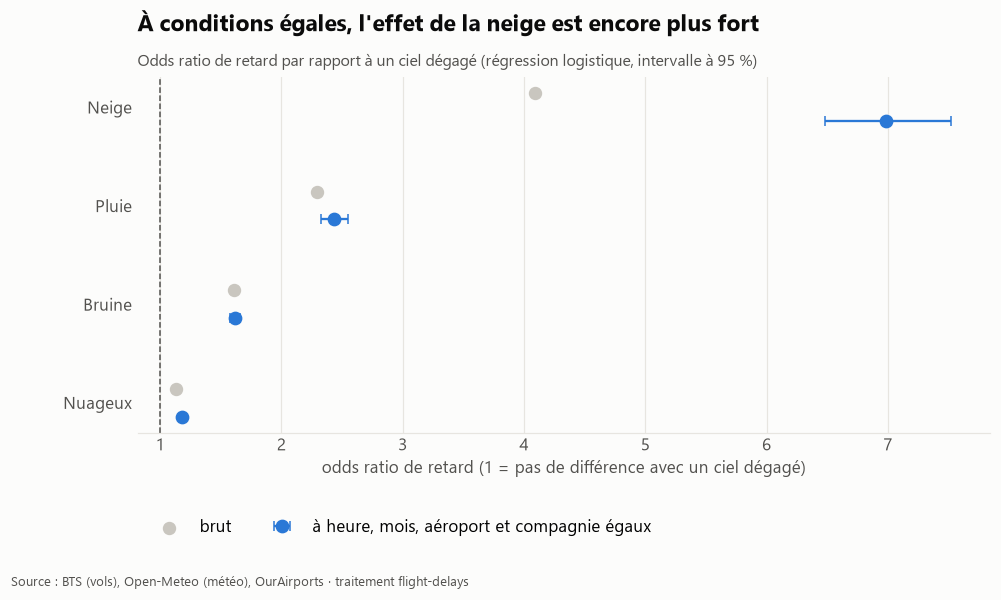

In [9]:
s = fd.sample(500_000, where="weather_condition IS NOT NULL AND NOT is_cancelled", con=con)
s["mois"] = pd.to_datetime(s.flight_date).dt.month
s["jour"] = pd.to_datetime(s.flight_date).dt.day_of_week
s["retard"] = s.is_delayed.astype(int)

logit = smf.logit(
    "retard ~ C(weather_condition, Treatment('Dégagé')) + C(sched_dep_hour) + C(mois) + C(jour) + C(origin) + C(carrier_code)",
    data=s).fit(disp=False, maxiter=200)

rows = [ix for ix in logit.params.index if ix.startswith("C(weather_condition")]
odds = pd.DataFrame({
    "meteo": [ix.split("[T.")[1].rstrip("]") for ix in rows],
    "odds_ratio": np.exp(logit.params[rows]).values,
    "ic_bas": np.exp(logit.conf_int().loc[rows, 0]).values,
    "ic_haut": np.exp(logit.conf_int().loc[rows, 1]).values,
    "p_value": logit.pvalues[rows].values,
}).sort_values("odds_ratio")

raw = w.set_index("meteo")
raw_or = (raw.retards / (raw.vols - raw.retards)) / (raw.loc["Dégagé", "retards"] / (raw.loc["Dégagé", "vols"] - raw.loc["Dégagé", "retards"]))
odds["odds_ratio_brut"] = odds.meteo.map(raw_or).values

fig, ax = plt.subplots(figsize=(10, 4.2))
y = np.arange(len(odds))
ax.scatter(odds.odds_ratio_brut, y + 0.14, color=fs.NEUTRAL, s=60, zorder=3, label="brut")
ax.errorbar(odds.odds_ratio, y - 0.14, xerr=[odds.odds_ratio - odds.ic_bas, odds.ic_haut - odds.odds_ratio],
            fmt="o", color=fs.BLUE, ecolor=fs.BLUE, ms=8, capsize=3, zorder=4, label="à heure, mois, aéroport et compagnie égaux")
ax.axvline(1, color=fs.MUTED, lw=1, ls="--")
ax.set_yticks(y, odds.meteo)
ax.set_xlabel("odds ratio de retard (1 = pas de différence avec un ciel dégagé)")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.2), ncol=2)
ax.set_title("À conditions égales, l'effet de la neige est encore plus fort")
fs.subtitle(ax, "Odds ratio de retard par rapport à un ciel dégagé (régression logistique, intervalle à 95 %)")
fs.source(fig, y=-0.2)
fs.save(fig, "06_meteo_ajustee")
print(f"Pseudo-R² de McFadden : {logit.prsquared:.3f}")
odds.round(3)

## 5. Question 4 : un avion en retard contamine-t-il ses vols suivants ?

Un même avion (identifié par son immatriculation) enchaîne plusieurs vols dans la journée. Une fonction de fenêtre `LAG` retrouve, pour chaque vol, le vol précédent du même avion le même jour.

In [10]:
casc = fd.query("""
    WITH legs AS (
        SELECT tail_number, flight_date, sched_dep_hhmm, is_delayed,
               LAG(is_delayed) OVER w AS prev_delayed,
               ROW_NUMBER() OVER w AS rang
        FROM fact_flights
        WHERE tail_number IS NOT NULL AND NOT is_cancelled
        WINDOW w AS (PARTITION BY tail_number, flight_date ORDER BY sched_dep_hhmm)
    )
    SELECT LEAST(rang, 6) AS rang, prev_delayed, COUNT(*) AS vols, SUM(is_delayed::INT) AS retards
    FROM legs GROUP BY 1, 2 ORDER BY 1, 2""", con)

t = casc.dropna(subset=["prev_delayed"]).groupby("prev_delayed")[["vols", "retards"]].sum()
p_yes, p_no = t.loc[True, "retards"] / t.loc[True, "vols"], t.loc[False, "retards"] / t.loc[False, "vols"]
table = np.array([[t.loc[True, "retards"], t.loc[True, "vols"] - t.loc[True, "retards"]],
                  [t.loc[False, "retards"], t.loc[False, "vols"] - t.loc[False, "retards"]]])
odds_ratio, _ = stats.fisher_exact(table) if table.sum() < 1e4 else (table[0, 0] * table[1, 1] / (table[0, 1] * table[1, 0]), None)
se = np.sqrt((1 / table).sum())
print(f"Vol précédent en retard   : {p_yes:.1%} de retards ({fd.fmt(t.loc[True, 'vols'])} vols)")
print(f"Vol précédent à l'heure   : {p_no:.1%} de retards ({fd.fmt(t.loc[False, 'vols'])} vols)")
print(f"Risque multiplié par      : {p_yes / p_no:.1f}")
print(f"Odds ratio                : {odds_ratio:.1f} (IC 95 % : {np.exp(np.log(odds_ratio) - 1.96*se):.1f} à {np.exp(np.log(odds_ratio) + 1.96*se):.1f})")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Vol précédent en retard   : 65.2% de retards (1 974 714 vols)
Vol précédent à l'heure   : 14.4% de retards (8 451 683 vols)
Risque multiplié par      : 4.5
Odds ratio                : 11.2 (IC 95 % : 11.2 à 11.2)


,vols,retards,pct
rang,,,
1,3455092,482906.0,14.0
2,3191474,610499.0,19.1
3,2719741,621997.0,22.9
4,2154374,573293.0,26.6
5,1290446,376979.0,29.2
6,1070362,318930.0,29.8


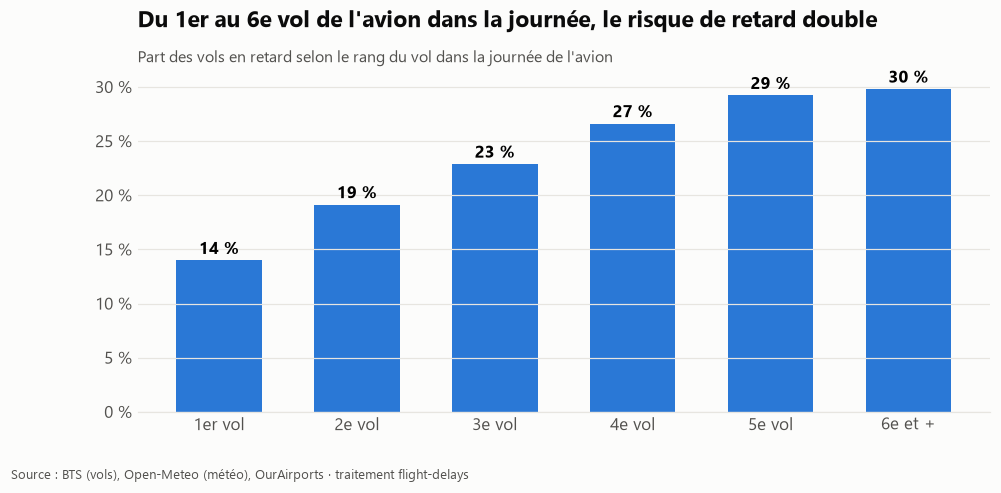

In [11]:
r = casc.groupby("rang")[["vols", "retards"]].sum()
r["pct"] = r.retards / r.vols * 100

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(r.index, r.pct, color=fs.BLUE, width=0.62)
for x, v in zip(r.index, r.pct):
    ax.text(x, v + 0.6, f"{v:.0f} %", ha="center", fontweight="bold")
ax.set_xticks(r.index, [f"{i}e vol" if i > 1 else "1er vol" for i in r.index[:-1]] + ["6e et +"])
fs.pct_axis(ax)
ax.set_title("Du 1er au 6e vol de l'avion dans la journée, le risque de retard double")
fs.subtitle(ax, "Part des vols en retard selon le rang du vol dans la journée de l'avion")
fs.source(fig)
fs.save(fig, "07_cascade")
r.round(1)

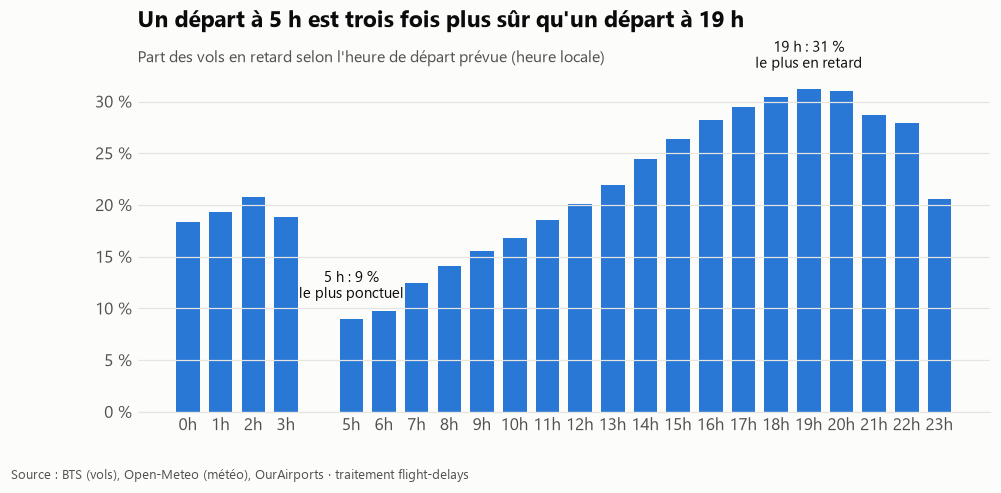

In [12]:
h = fd.query("""
    SELECT sched_dep_hour AS heure, COUNT(*) AS vols, AVG(is_delayed::INT) * 100 AS pct
    FROM fact_flights WHERE NOT is_cancelled GROUP BY 1 ORDER BY 1""", con)
h = h[h.vols >= 1000]

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(h.heure, h.pct, color=fs.BLUE, width=0.72)
best, worst = h.loc[h.pct.idxmin()], h.loc[h.pct.idxmax()]
for row, lab in [(best, "le plus ponctuel"), (worst, "le plus en retard")]:
    ax.annotate(f"{int(row.heure)} h : {row.pct:.0f} %\n{lab}", (row.heure, row.pct), xytext=(0, 14),
                textcoords="offset points", ha="center", fontsize=9.5, color=fs.INK)
ax.set_xticks(h.heure, [f"{int(x)}h" for x in h.heure])
fs.pct_axis(ax)
ax.set_title("Un départ à 5 h est trois fois plus sûr qu'un départ à 19 h")
fs.subtitle(ax, "Part des vols en retard selon l'heure de départ prévue (heure locale)")
fs.source(fig)
fs.save(fig, "08_heure_depart")

## 6. Question 5 : quelles compagnies et quels aéroports sont les plus fiables ?

### 6.1 Compagnies, avec intervalle de confiance

,compagnie,type,vols,pct,ic_bas,ic_haut
4,Endeavor Air,Régionale,200094,15.43,15.28,15.59
7,Hawaiian Airlines,Grande compagnie,158614,16.21,16.03,16.39
10,Republic Airways,Régionale,647501,17.52,17.42,17.61
3,Delta Air Lines,Grande compagnie,2035506,18.31,18.26,18.36
11,SkyWest Airlines,Régionale,1584479,19.59,19.53,19.65
14,United Airlines,Grande compagnie,1555722,20.37,20.31,20.44
5,Envoy Air,Régionale,579277,20.51,20.41,20.62
12,Southwest Airlines,Low cost,2811304,20.77,20.73,20.82
0,Alaska Airlines,Grande compagnie,491407,22.17,22.05,22.28
13,Spirit Airlines,Ultra low cost,455618,22.41,22.29,22.53


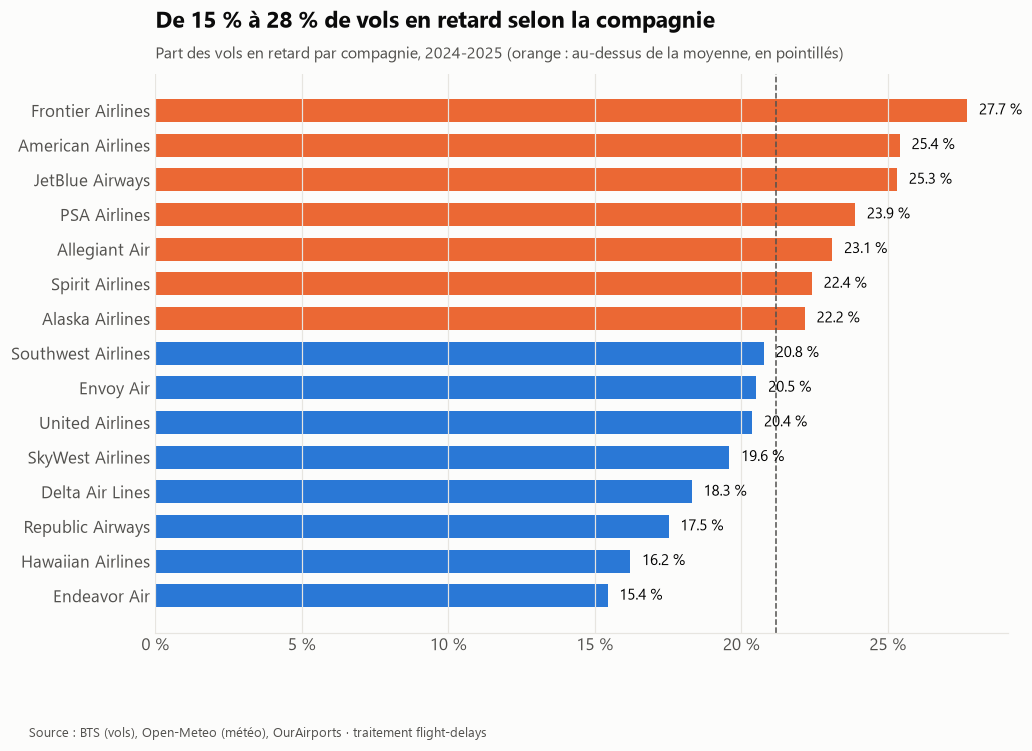

In [13]:
c = fd.query("""
    SELECT c.carrier_name AS compagnie, c.carrier_type AS type, d.year AS annee,
           COUNT(*) AS vols, SUM(f.is_delayed::INT) AS retards, AVG(f.is_cancelled::INT) * 100 AS pct_annule
    FROM fact_flights f JOIN dim_carrier c USING (carrier_code) JOIN dim_date d ON d.date = f.flight_date
    GROUP BY ALL""", con)
tot = c.groupby(["compagnie", "type"], as_index=False)[["vols", "retards"]].sum()
tot = tot[tot.vols >= 20_000].copy()
tot["pct"] = tot.retards / tot.vols * 100
lo, hi = wilson(tot.retards, tot.vols)
tot["ic_bas"], tot["ic_haut"] = lo * 100, hi * 100
tot = tot.sort_values("pct")

fig, ax = plt.subplots(figsize=(10, 0.36 * len(tot) + 1.2))
mean = tot.retards.sum() / tot.vols.sum() * 100
colors = [fs.ORANGE if p > mean else fs.BLUE for p in tot.pct]
ax.barh(tot.compagnie, tot.pct, color=colors, height=0.66)
ax.axvline(mean, color=fs.MUTED, lw=1, ls="--")
for i, v in enumerate(tot.pct):
    ax.text(v + 0.4, i, f"{v:.1f} %", va="center", fontsize=9.5)
fs.pct_axis(ax, "x")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title("De 15 % à 28 % de vols en retard selon la compagnie")
fs.subtitle(ax, "Part des vols en retard par compagnie, 2024-2025 (orange : au-dessus de la moyenne, en pointillés)")
fs.source(fig)
fs.save(fig, "09_compagnies")
tot[["compagnie", "type", "vols", "pct", "ic_bas", "ic_haut"]].round(2)

### 6.2 Ce classement est-il stable d'une année à l'autre ?

Si une compagnie est ponctuelle par hasard, son rang devrait changer l'année suivante. Si c'est une vraie qualité d'organisation, il devrait se maintenir.

Corrélation des rangs (Spearman) entre 2024 et 2025 : 0.81 (p = 0.000, 14 compagnies)


annee,2024,2025
compagnie,,
Alaska Airlines,21.6,22.8
Allegiant Air,21.2,24.8
American Airlines,25.7,25.2
Delta Air Lines,17.1,19.5
Envoy Air,20.5,20.5
Frontier Airlines,28.0,27.4
Hawaiian Airlines,15.3,17.1
JetBlue Airways,25.0,25.6
PSA Airlines,21.4,26.2


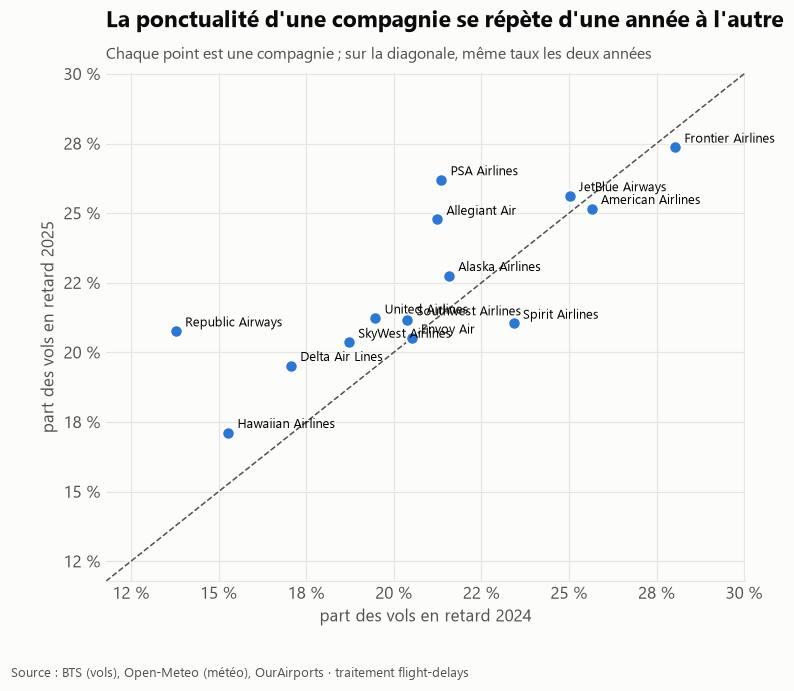

In [14]:
y = c.assign(pct=c.retards / c.vols * 100).pivot_table(index="compagnie", columns="annee", values="pct")
y = y.dropna()
if y.shape[1] >= 2 and len(y) >= 4:
    a, b = y.columns[:2]
    rho, p = stats.spearmanr(y[a], y[b])
    print(f"Corrélation des rangs (Spearman) entre {a} et {b} : {rho:.2f} (p = {p:.3f}, {len(y)} compagnies)")

    fig, ax = plt.subplots(figsize=(7.5, 6))
    ax.scatter(y[a], y[b], color=fs.BLUE, s=70, edgecolor=fs.SURFACE, linewidth=1.5, zorder=3)
    lim = [min(y.min()) - 2, max(y.max()) + 2]
    ax.plot(lim, lim, color=fs.MUTED, ls="--", lw=1)
    for name, row in y.iterrows():
        ax.annotate(name, (row[a], row[b]), xytext=(6, 3), textcoords="offset points", fontsize=8.5)
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.grid(axis="x")
    fs.pct_axis(ax); fs.pct_axis(ax, "x")
    ax.set_xlabel(f"part des vols en retard {a}"); ax.set_ylabel(f"part des vols en retard {b}")
    ax.set_title("La ponctualité d'une compagnie se répète d'une année à l'autre")
    fs.subtitle(ax, "Chaque point est une compagnie ; sur la diagonale, même taux les deux années")
    fs.source(fig)
    fs.save(fig, "10_stabilite_compagnies")
y.round(1)

### 6.3 Aéroports

,code,ville,etat,latitude,longitude,vols,pct
63,DFW,Dallas-Fort Worth,TX,32.9,-97.0,629436,27.2
2,MIA,Miami,FL,25.8,-80.3,221851,26.4
71,CLT,Charlotte,NC,35.2,-80.9,412980,25.5
62,FLL,Fort Lauderdale,FL,26.1,-80.2,179475,24.9
81,ORD,Chicago,IL,42.0,-87.9,607080,24.7
12,MCO,Orlando,FL,28.4,-81.3,319601,24.1
0,DEN,Denver,CO,39.9,-104.7,626331,24.0
72,PHL,Philadelphia,PA,39.9,-75.2,198154,23.8
27,AVL,Asheville,NC,35.4,-82.5,22325,23.3
59,BWI,Baltimore,MD,39.2,-76.7,194672,23.3


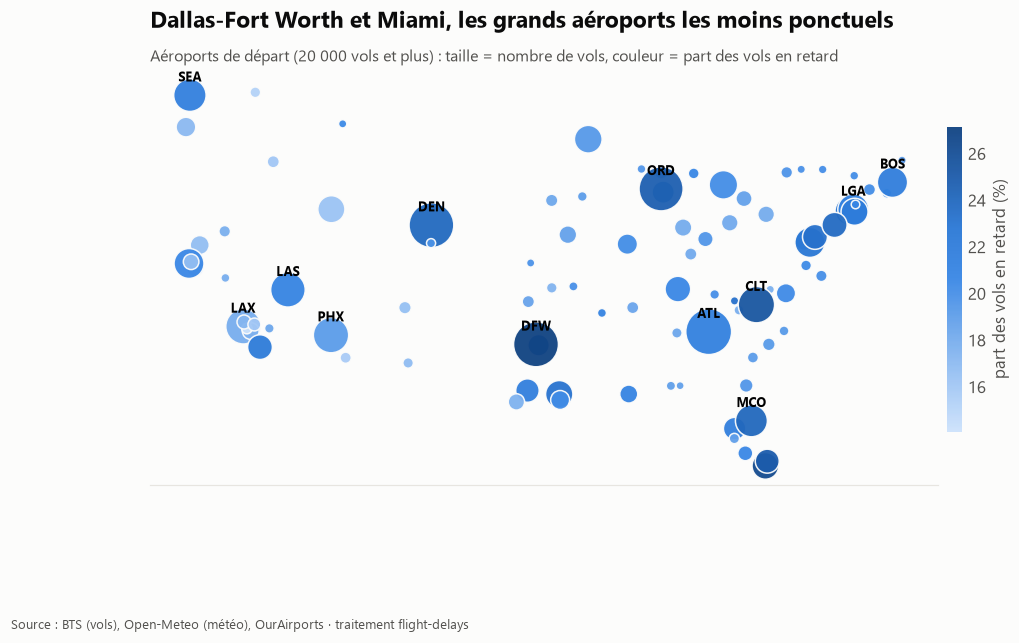

In [15]:
ap = fd.query("""
    SELECT a.airport_code AS code, a.city AS ville, a.state AS etat, a.latitude, a.longitude,
           COUNT(*) AS vols, AVG(f.is_delayed::INT) * 100 AS pct
    FROM fact_flights f JOIN dim_airport a ON a.airport_code = f.origin
    WHERE a.latitude BETWEEN 24 AND 50 AND a.longitude BETWEEN -125 AND -66
    GROUP BY ALL HAVING COUNT(*) >= 20000""", con)

fig, ax = plt.subplots(figsize=(11, 6))
sc = ax.scatter(ap.longitude, ap.latitude, s=ap.vols / ap.vols.max() * 900, c=ap.pct,
                cmap=plt.matplotlib.colors.LinearSegmentedColormap.from_list("b", fs.BLUE_RAMP),
                edgecolor=fs.SURFACE, linewidth=1, alpha=0.95)
for _, row in ap.nlargest(12, "vols").iterrows():
    ax.annotate(row.code, (row.longitude, row.latitude), xytext=(0, 9), textcoords="offset points", ha="center", fontsize=8.5, fontweight="bold")
cb = fig.colorbar(sc, ax=ax, shrink=0.6, pad=0.01)
cb.set_label("part des vols en retard (%)", color=fs.MUTED)
cb.outline.set_visible(False)
ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
ax.set_aspect(1.25)
ax.set_title("Dallas-Fort Worth et Miami, les grands aéroports les moins ponctuels")
fs.subtitle(ax, "Aéroports de départ (20 000 vols et plus) : taille = nombre de vols, couleur = part des vols en retard")
fs.source(fig)
fs.save(fig, "11_aeroports")
ap.sort_values("pct", ascending=False).head(10).round(1)

## Ce qu'il faut retenir

1. **Le premier facteur de retard, c'est le retard lui-même.** Quand l'avion arrive en retard de son vol précédent, son vol suivant est en retard dans 65 % des cas, contre 14 % sinon (risque multiplié par 4,5). C'est aussi la première cause déclarée : 40 % des minutes de retard.
2. **L'heure du départ compte énormément.** 8,9 % de retards pour un départ à 5 h, 31 % à 19 h : les retards s'accumulent au fil de la journée, rotation après rotation (14 % au premier vol de l'avion, 30 % à partir du sixième).
3. **La météo pèse peu en volume, mais lourd quand elle frappe.** La météo extrême ne représente que 6 % des minutes de retard déclarées. Pourtant, sous la neige, la moitié des vols partent en retard et 10 % sont annulés ; à heure, saison, aéroport et compagnie égaux, la cote d'un retard est multipliée par 7 par rapport à un ciel dégagé, et par 2,4 sous la pluie.
4. **Les compagnies ne se valent pas, et durablement.** De 15 % (Endeavor Air) à 28 % (Frontier) de vols en retard ; le classement de 2024 se retrouve en 2025 (corrélation des rangs de 0,81).
5. **Octobre-novembre 2025 montre la fragilité du système** : +5 à +7 points de retards par rapport à 2024, pendant le shutdown fédéral qui a désorganisé le contrôle aérien.